# 01 — Presidential Candidates Ranking & Vote Share Analysis
**Eleição Ordinária Federal 2026 (`ele=6257`) — 1º Turno — Presidente (Brasil)**

This notebook loads the official TSE (Tribunal Superior Eleitoral) election snapshot JSON files from `data/` and explores the performance of all **12 presidential candidates**:
1. **Complete Ranking Table**: Candidate numbers, parties, coalitions/federations, vice-presidential running mates, ages on election day (`04/10/2026`), nominal votes (`vap`), exact vote share (`pvapn`), and runoff qualification status (`st`).
2. **Vote Totals & Share Visualization**: Two-panel horizontal bar chart showing both the overall race (led by **Flavio Bolsonaro** and **Lula** advancing to the 2nd round) and a zoomed view of the 3rd–12th place candidates.
3. **Vote Concentration & Pareto Curve**: Donut chart and cumulative Lorenz/Pareto distribution highlighting the 92.19% concentration among the top two candidates.
4. **Candidate Demographics & Ticket Composition**: Age profile of the presidential field on election day (`04/10/2026`) alongside vote performance and vice-presidential party alliances.

In [1]:
%matplotlib inline
import json
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

# Resolve repository root whether executed from repo root or test/ directory
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
SCRIPTS_DIR = REPO_ROOT / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import scrape_tse

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 120
sns.set_theme(style="whitegrid", palette="deep")

snapshot_files = sorted(DATA_DIR.glob("presidente_br_*.json"))
latest_path = snapshot_files[-1]
with latest_path.open(encoding="utf-8") as fh:
    latest_doc = json.load(fh)

meta = latest_doc["metadata"]
payload = latest_doc["data"]
scrape_tse.validate_payload(payload)

print(f"Loaded latest snapshot: {latest_path.name}")
print(f"TSE file generated at : {meta['tse_file_generated_at']} (last updated: {meta['tse_last_updated_at']})")
print(f"Scraped at (UTC)      : {meta['scraped_at_utc']} | (Brasília): {meta['scraped_at_brasilia']}")
print(f"Sections totalized    : {payload['s']['st']}/{payload['s']['ts']} ({payload['s']['pst']}%)")

Loaded latest snapshot: presidente_br_20261014_192215Z.json
TSE file generated at : 05/10/2026 12:51:47 (last updated: 05/10/2026 12:51:05)
Scraped at (UTC)      : 2026-10-14T19:22:15Z | (Brasília): 2026-10-14T16:22:15-03:00
Sections totalized    : 499248/499248 (100,00%)


In [2]:
# Flatten candidate records with full party, coalition, vice-candidate, and demographic details
election_date = datetime.strptime(payload["dg"], "%d/%m/%Y")

records = []
for cargo in payload.get("carg", []):
    for agr in cargo.get("agr", []):
        for par in agr.get("par", []):
            for cand in par.get("cand", []):
                vice = (cand.get("vs") or [{}])[0]
                bday = datetime.strptime(cand["dt"], "%d/%m/%Y")
                age_years = (election_date - bday).days / 365.2425
                records.append({
                    "rank": int(cand["seq"]),
                    "number": int(cand["n"]),
                    "ballot_name": cand["nmu"],
                    "full_name": cand["nm"],
                    "party": par["sg"],
                    "aggregation_type": "Coligação" if agr.get("tp") == "c" else "Partido Isolado",
                    "coalition_or_party": agr.get("nm"),
                    "composition": agr.get("com"),
                    "vice_ballot_name": vice.get("nmu", ""),
                    "vice_party": vice.get("sgp", ""),
                    "birthdate": cand["dt"],
                    "age_on_election": round(age_years, 1),
                    "votes": int(cand["vap"]),
                    "pct_display": cand["pvap"],
                    "pct_exact": float(cand["pvapn"].replace(",", ".")),
                    "qualified_runoff": cand.get("e") == "s",
                    "status": cand.get("st", ""),
                })

df_cands = pd.DataFrame(records).sort_values("rank").reset_index(drop=True)
df_cands["cumulative_pct"] = df_cands["pct_exact"].cumsum()

display_cols = [
    "rank", "number", "ballot_name", "party", "vice_ballot_name",
    "vice_party", "age_on_election", "votes", "pct_exact", "status"
]
df_cands[display_cols]

,rank,number,ballot_name,party,vice_ballot_name,vice_party,age_on_election,votes,pct_exact,status
0,1,22,FLAVIO BOLSONARO,PL,ALFREDO GASPAR,PL,45.4,56104503,47.027772,2º turno
1,2,13,LULA,PT,GERALDO ALCKMIN,PSB,81.0,53879538,45.162768,2º turno
2,3,70,ESCRITOR AUGUSTO CURY,AVANTE,JÚLIO DELGADO,AVANTE,68.0,3448569,2.890651,Não eleito
3,4,14,RENAN SANTOS,MISSÃO,CORONEL MEDINA,MISSÃO,42.6,2675887,2.242975,Não eleito
4,5,55,RONALDO CAIADO,PSD,GILBERTO KASSAB,PSD,77.0,2605148,2.183680,Não eleito
5,6,30,ZEMA,NOVO,EDUARDO GIRÃO,NOVO,61.9,326488,0.273668,Não eleito
6,7,80,SAMARA,UP,RAQUEL BRÍCIO,UP,39.1,122911,0.103026,Não eleito
7,8,16,HERTZ DIAS,PSTU,VANESSA PORTUGAL,PSTU,56.0,43103,0.036130,Não eleito
8,9,27,CLARIANA BARAO,DC,FABIANA TORQUATO,DC,39.5,40043,0.033565,Não eleito
9,10,21,EDMILSON COSTA,PCB,CLEUSA SANTOS,PCB,76.5,22693,0.019022,Não eleito


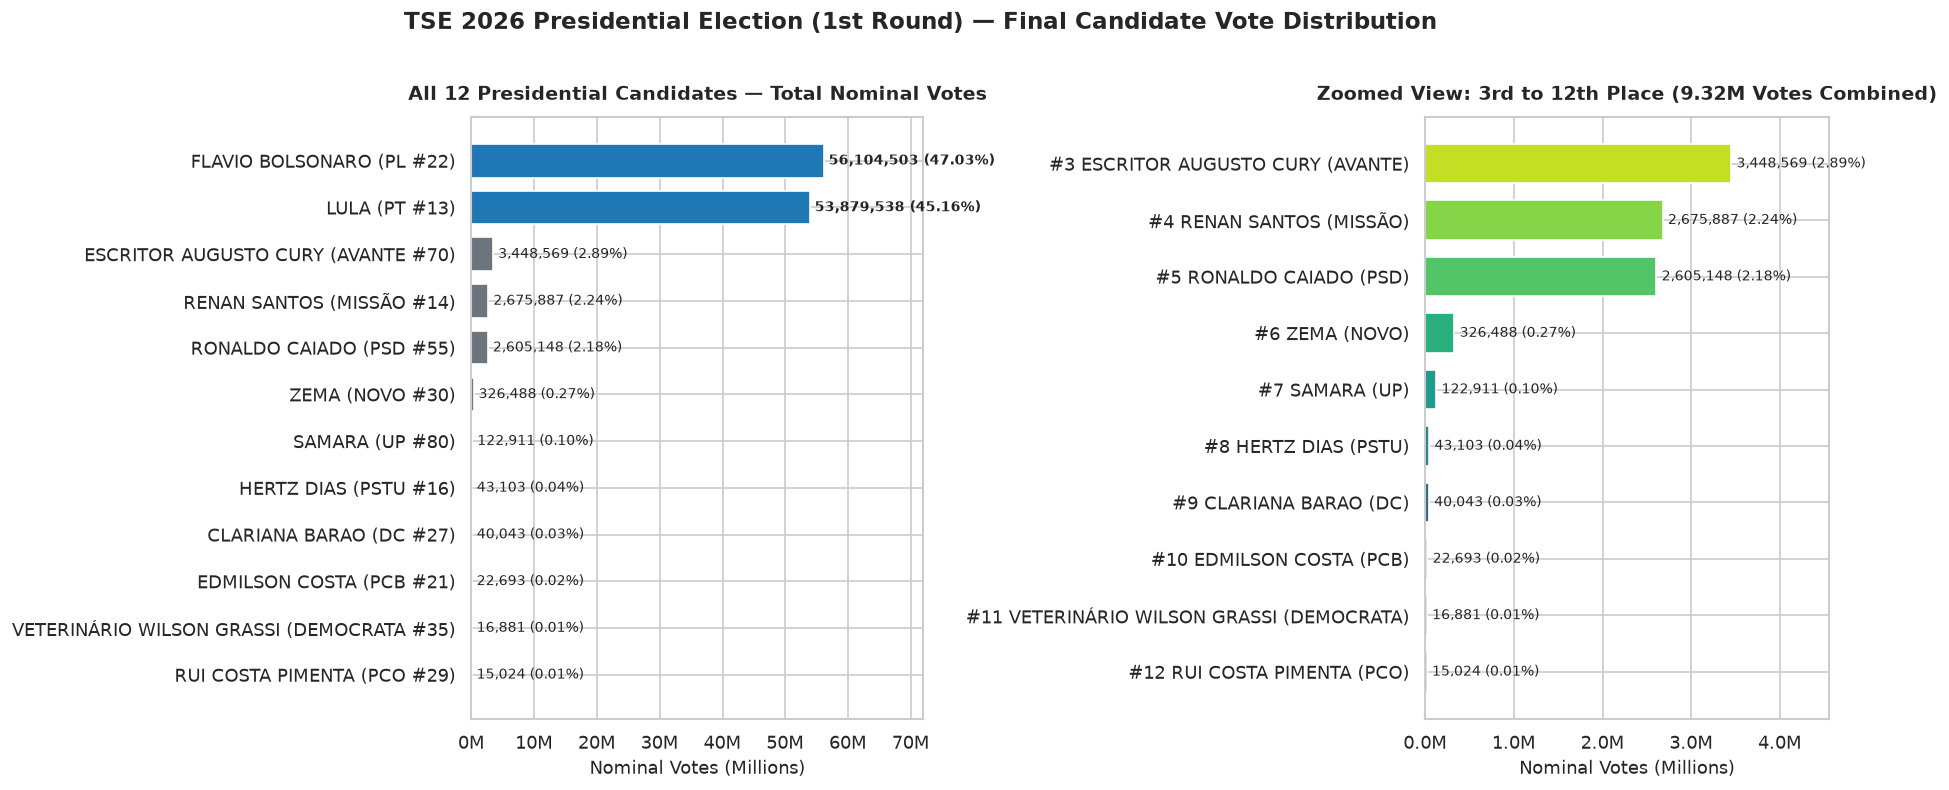

In [3]:
# Graph 1: Two-panel Horizontal Bar Chart (All Candidates vs Zoomed 3rd-12th Place)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.5), gridspec_kw={"width_ratios": [1.12, 1]})

# Left panel: All 12 candidates
df_sorted = df_cands.sort_values("votes", ascending=True)
colors_all = ["#1f77b4" if st == "2º turno" else "#6c757d" for st in df_sorted["status"]]
labels_all = [f"{r['ballot_name']} ({r['party']} #{r['number']})" for _, r in df_sorted.iterrows()]

bars1 = ax1.barh(labels_all, df_sorted["votes"] / 1e6, color=colors_all, edgecolor="white", height=0.72)
ax1.set_title("All 12 Presidential Candidates — Total Nominal Votes", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("Nominal Votes (Millions)", fontsize=10.5)
ax1.set_xlim(0, 72)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))

for bar, (_, row) in zip(bars1, df_sorted.iterrows()):
    w = bar.get_width()
    ax1.text(
        w + 0.8, bar.get_y() + bar.get_height() / 2,
        f"{row['votes']:,.0f} ({row['pct_exact']:.2f}%)",
        va="center", ha="left", fontsize=8.5,
        fontweight="bold" if row["qualified_runoff"] else "normal"
    )

# Right panel: 3rd to 12th place candidates zoomed
df_minor = df_cands[df_cands["rank"] >= 3].sort_values("votes", ascending=True)
labels_minor = [f"#{r['rank']} {r['ballot_name']} ({r['party']})" for _, r in df_minor.iterrows()]
palette_minor = sns.color_palette("viridis", len(df_minor))

bars2 = ax2.barh(labels_minor, df_minor["votes"] / 1e6, color=palette_minor, edgecolor="white", height=0.7)
ax2.set_title("Zoomed View: 3rd to 12th Place (9.32M Votes Combined)", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_xlabel("Nominal Votes (Millions)", fontsize=10.5)
ax2.set_xlim(0, 4.55)
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.1f}M"))

for bar, (_, row) in zip(bars2, df_minor.iterrows()):
    w = bar.get_width()
    ax2.text(
        w + 0.06, bar.get_y() + bar.get_height() / 2,
        f"{row['votes']:,.0f} ({row['pct_exact']:.2f}%)",
        va="center", ha="left", fontsize=8.5
    )

fig.suptitle("TSE 2026 Presidential Election (1st Round) — Final Candidate Vote Distribution", fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

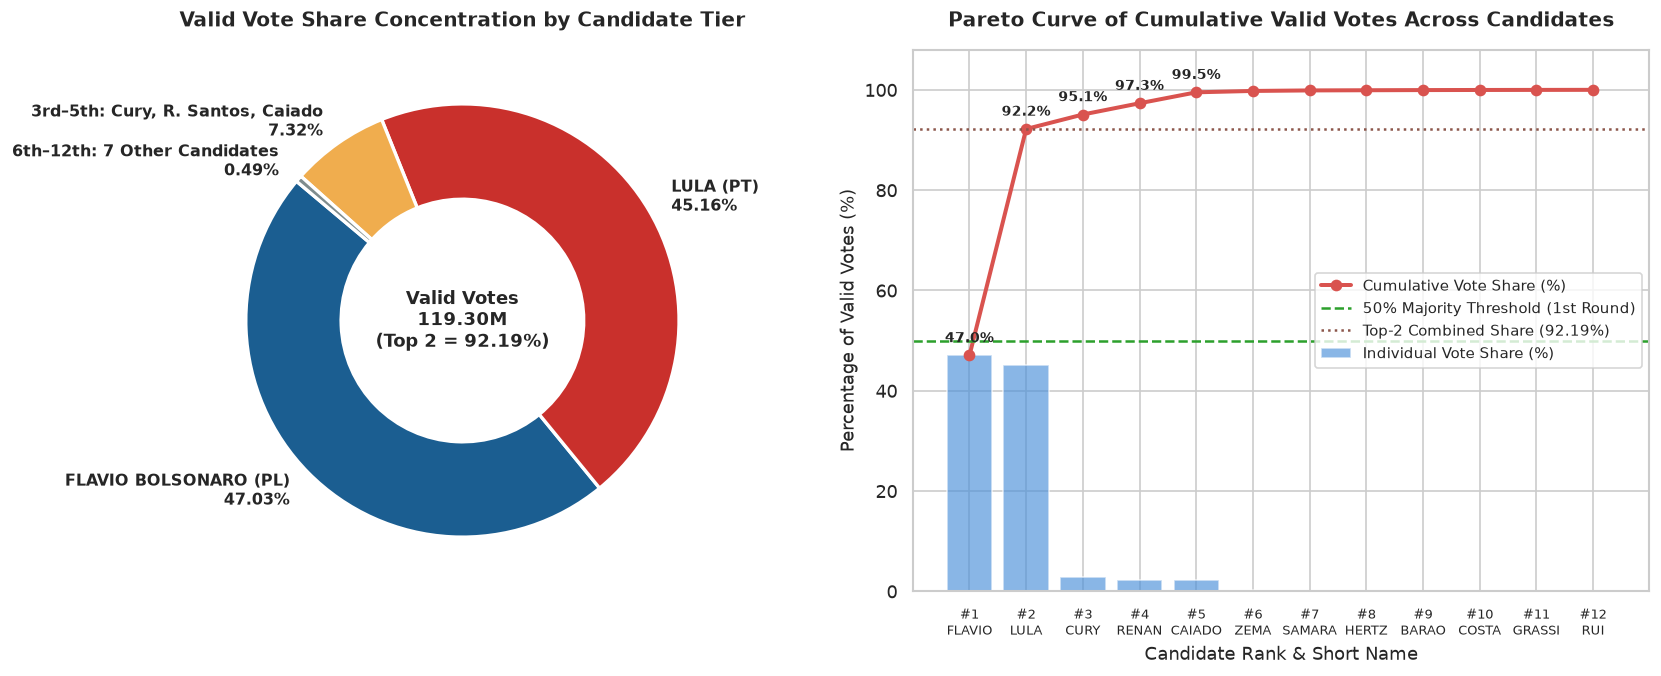

In [4]:
# Graph 2: Vote Concentration Donut Chart & Cumulative Pareto Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.8))

# Group into top tiers for clear donut visualization
top1 = df_cands.iloc[0]
top2 = df_cands.iloc[1]
tier_mid = df_cands.iloc[2:5]  # Cury, Renan Santos, Caiado
tier_tail = df_cands.iloc[5:]  # Remaining 7 candidates

tier_labels = [
    f"{top1['ballot_name']} ({top1['party']})\n{top1['pct_exact']:.2f}%",
    f"{top2['ballot_name']} ({top2['party']})\n{top2['pct_exact']:.2f}%",
    f"3rd–5th: Cury, R. Santos, Caiado\n{tier_mid['pct_exact'].sum():.2f}%",
    f"6th–12th: 7 Other Candidates\n{tier_tail['pct_exact'].sum():.2f}%",
]
tier_votes = [
    top1["votes"],
    top2["votes"],
    tier_mid["votes"].sum(),
    tier_tail["votes"].sum(),
]
tier_colors = ["#1b5e91", "#c9302c", "#f0ad4e", "#7f8c8d"]

wedges, texts = ax1.pie(
    tier_votes,
    labels=tier_labels,
    colors=tier_colors,
    startangle=140,
    wedgeprops={"width": 0.44, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 9.5, "fontweight": "bold"},
    labeldistance=1.12,
)
ax1.text(0, 0, f"Valid Votes\n{df_cands['votes'].sum()/1e6:.2f}M\n(Top 2 = 92.19%)",
         ha="center", va="center", fontsize=10.5, fontweight="bold")
ax1.set_title("Valid Vote Share Concentration by Candidate Tier", fontsize=12, fontweight="bold", pad=14)

# Right panel: Cumulative Pareto Curve
x_ranks = df_cands["rank"]
y_cum = df_cands["cumulative_pct"]
ax2.bar(x_ranks, df_cands["pct_exact"], color="#4a90d9", alpha=0.65, label="Individual Vote Share (%)")
ax2.plot(x_ranks, y_cum, color="#d9534f", marker="o", linewidth=2.4, label="Cumulative Vote Share (%)")
ax2.axhline(50.0, color="#2ca02c", linestyle="--", linewidth=1.5, label="50% Majority Threshold (1st Round)")
ax2.axhline(92.19, color="#8c564b", linestyle=":", linewidth=1.5, label="Top-2 Combined Share (92.19%)")

for r, cum in zip(x_ranks[:5], y_cum[:5]):
    ax2.annotate(f"{cum:.1f}%", (r, cum), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5, fontweight="bold")

short_names = ["FLAVIO", "LULA", "CURY", "RENAN", "CAIADO", "ZEMA", "SAMARA", "HERTZ", "BARAO", "COSTA", "GRASSI", "RUI"]
ax2.set_xticks(x_ranks)
ax2.set_xticklabels([f"#{r}\n{sn}" for r, sn in zip(df_cands["rank"], short_names)], fontsize=8)
ax2.set_ylim(0, 108)
ax2.set_ylabel("Percentage of Valid Votes (%)", fontsize=10.5)
ax2.set_xlabel("Candidate Rank & Short Name", fontsize=10.5)
ax2.set_title("Pareto Curve of Cumulative Valid Votes Across Candidates", fontsize=12, fontweight="bold", pad=14)
ax2.legend(loc="center right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

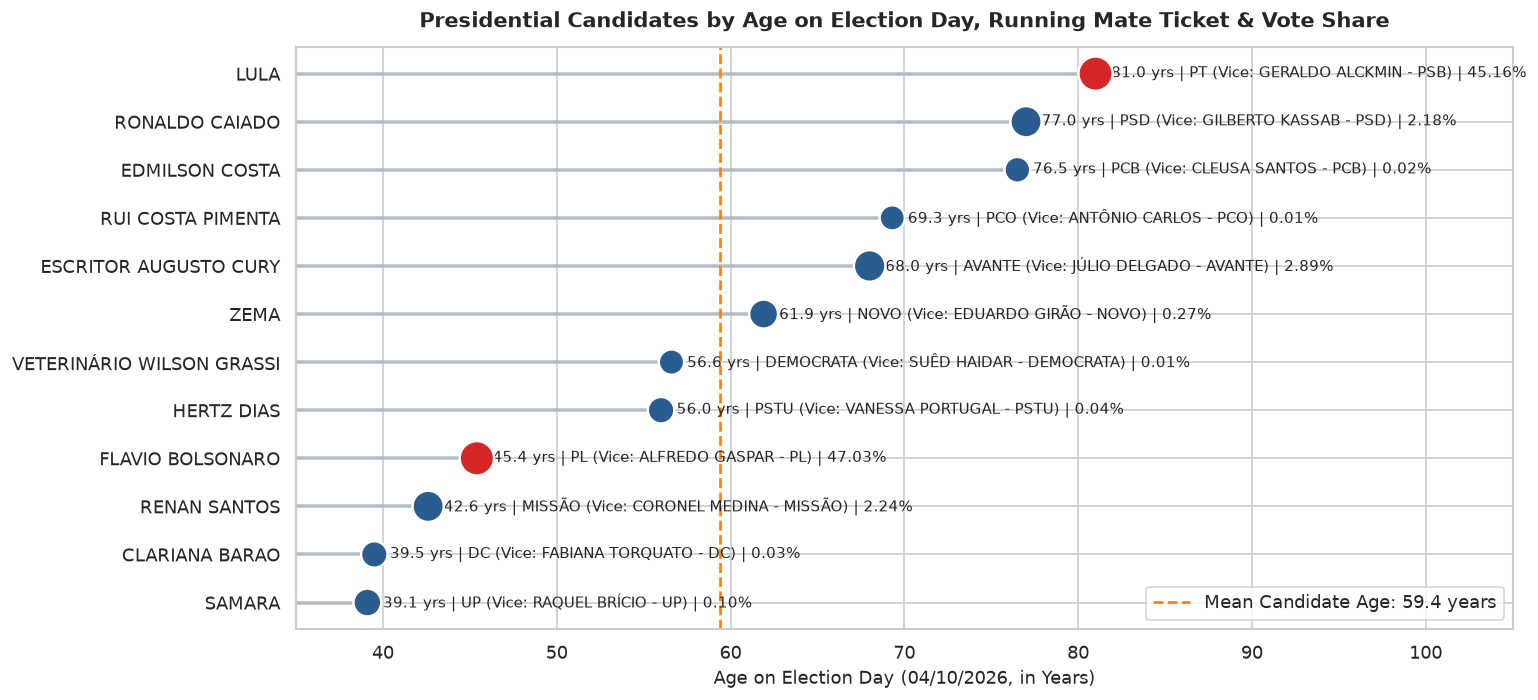

In [5]:
# Graph 3: Candidate Age Profile on Election Day (04/10/2026) & Ticket Alliance Profile
fig, ax = plt.subplots(figsize=(13, 6))

df_age = df_cands.sort_values("age_on_election", ascending=True).reset_index(drop=True)
sizes = np.log10(df_age["votes"]) * 55
colors = ["#d62728" if q else "#2b5c8f" for q in df_age["qualified_runoff"]]

ax.hlines(y=df_age["ballot_name"], xmin=35, xmax=df_age["age_on_election"], color="#adb5bd", alpha=0.8, linewidth=2.2)
scatter = ax.scatter(df_age["age_on_election"], df_age["ballot_name"], s=sizes, c=colors, zorder=4, edgecolors="white", linewidth=1.5)

for _, row in df_age.iterrows():
    ticket_info = f"{row['age_on_election']:.1f} yrs | {row['party']} (Vice: {row['vice_ballot_name']} - {row['vice_party']}) | {row['pct_exact']:.2f}%"
    ax.text(row["age_on_election"] + 0.9, row["ballot_name"], ticket_info, va="center", fontsize=8.8)

ax.axvline(df_age["age_on_election"].mean(), color="#ff7f0e", linestyle="--", linewidth=1.6,
           label=f"Mean Candidate Age: {df_age['age_on_election'].mean():.1f} years")
ax.set_xlim(35, 105)
ax.set_xlabel("Age on Election Day (04/10/2026, in Years)", fontsize=10.5)
ax.set_title("Presidential Candidates by Age on Election Day, Running Mate Ticket & Vote Share", fontsize=12.5, fontweight="bold", pad=12)
ax.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()